In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load prepared dataset
df = pd.read_csv("data/credit_approval_dataset.csv")

# Display basic information
print("Dataset shape:", df.shape)

display(df.head())

print("\nDataset information:")
df.info()


Dataset shape: (36457, 18)


,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,credit_risk
0,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,1
1,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,1
2,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0,0
3,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0,0
4,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 36457 entries, 0 to 36456
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CODE_GENDER          36457 non-null  str    
 1   FLAG_OWN_CAR         36457 non-null  str    
 2   FLAG_OWN_REALTY      36457 non-null  str    
 3   CNT_CHILDREN         36457 non-null  int64  
 4   AMT_INCOME_TOTAL     36457 non-null  float64
 5   NAME_INCOME_TYPE     36457 non-null  str    
 6   NAME_EDUCATION_TYPE  36457 non-null  str    
 7   NAME_FAMILY_STATUS   36457 non-null  str    
 8   NAME_HOUSING_TYPE    36457 non-null  str    
 9   DAYS_BIRTH           36457 non-null  int64  
 10  DAYS_EMPLOYED        36457 non-null  int64  
 11  FLAG_MOBIL           36457 non-null  int64  
 12  FLAG_WORK_PHONE      36457 non-null  int64  
 13  FLAG_PHONE           36457 non-null  int64  
 14  FLAG_EMAIL           36457 non-null  int64  
 15  OCCUPATION_TYPE      2513

In [2]:

# Check missing values
print("Missing values:")
print(df.isnull().sum().sort_values(ascending=False))

# Check duplicates
print("\nDuplicate records:", df.duplicated().sum())

# Missing value percentage
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

print("\nMissing percentage:")
print(missing_percentage[missing_percentage > 0])


Missing values:
OCCUPATION_TYPE        11323
CODE_GENDER                0
FLAG_OWN_CAR               0
FLAG_OWN_REALTY            0
AMT_INCOME_TOTAL           0
CNT_CHILDREN               0
NAME_EDUCATION_TYPE        0
NAME_FAMILY_STATUS         0
NAME_HOUSING_TYPE          0
NAME_INCOME_TYPE           0
DAYS_BIRTH                 0
DAYS_EMPLOYED              0
FLAG_WORK_PHONE            0
FLAG_MOBIL                 0
FLAG_PHONE                 0
FLAG_EMAIL                 0
CNT_FAM_MEMBERS            0
credit_risk                0
dtype: int64

Duplicate records: 25063

Missing percentage:
OCCUPATION_TYPE    31.058507
dtype: float64


credit_risk
0    32166
1     4291
Name: count, dtype: int64

Target percentages:
credit_risk
0    88.22997
1    11.77003
Name: proportion, dtype: float64


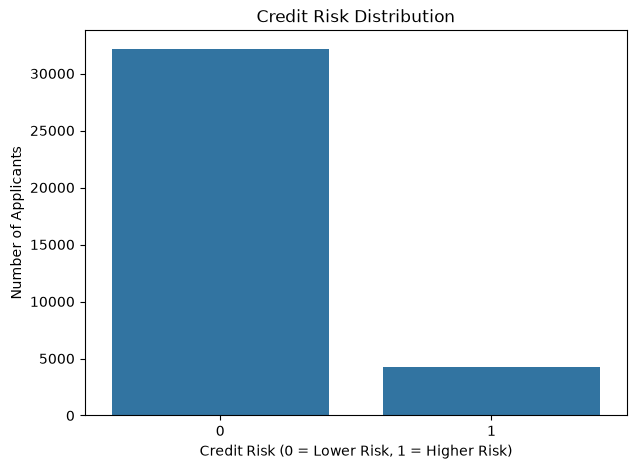

In [3]:

# Target distribution
print(df["credit_risk"].value_counts())

print("\nTarget percentages:")
print(df["credit_risk"].value_counts(normalize=True) * 100)

# Visualize target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="credit_risk")

plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk (0 = Lower Risk, 1 = Higher Risk)")
plt.ylabel("Number of Applicants")

plt.show()


,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,credit_risk
count,36457.000000,3.645700e+04,36457.000000,36457.000000,36457.0,36457.000000,36457.000000,36457.000000,36457.000000,36457.000000
mean,0.430315,1.866857e+05,-15975.173382,59262.935568,1.0,0.225526,0.294813,0.089722,2.198453,0.117700
std,0.742367,1.017892e+05,4200.549944,137651.334859,0.0,0.417934,0.455965,0.285787,0.911686,0.322257
min,0.000000,2.700000e+04,-25152.000000,-15713.000000,1.0,0.000000,0.000000,0.000000,1.000000,0.000000
25%,0.000000,1.215000e+05,-19438.000000,-3153.000000,1.0,0.000000,0.000000,0.000000,2.000000,0.000000
50%,0.000000,1.575000e+05,-15563.000000,-1552.000000,1.0,0.000000,0.000000,0.000000,2.000000,0.000000
75%,1.000000,2.250000e+05,-12462.000000,-408.000000,1.0,0.000000,1.000000,0.000000,3.000000,0.000000
max,19.000000,1.575000e+06,-7489.000000,365243.000000,1.0,1.000000,1.000000,1.000000,20.000000,1.000000


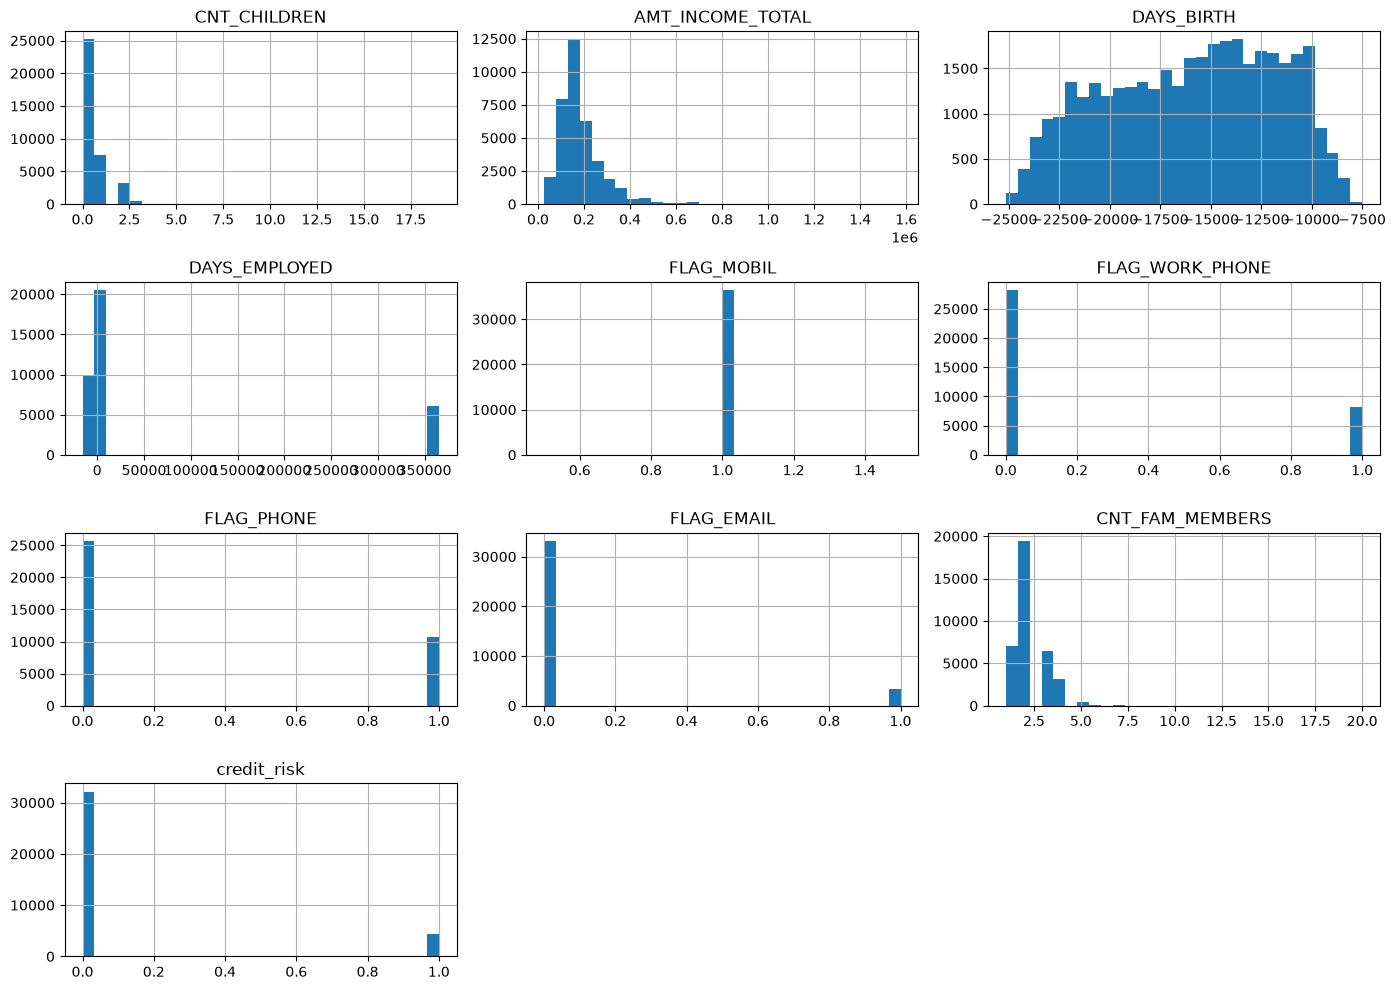

In [4]:

# Identify numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Summary statistics
display(df[numerical_columns].describe())

# Plot numerical distributions
df[numerical_columns].hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()


In [5]:

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical columns:", categorical_columns)

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts().head(10))


Categorical columns: ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']

CODE_GENDER
CODE_GENDER
F    24430
M    12027
Name: count, dtype: int64

FLAG_OWN_CAR
FLAG_OWN_CAR
N    22614
Y    13843
Name: count, dtype: int64

FLAG_OWN_REALTY
FLAG_OWN_REALTY
Y    24506
N    11951
Name: count, dtype: int64

NAME_INCOME_TYPE
NAME_INCOME_TYPE
Working                 18819
Commercial associate     8490
Pensioner                6152
State servant            2985
Student                    11
Name: count, dtype: int64

NAME_EDUCATION_TYPE
NAME_EDUCATION_TYPE
Secondary / secondary special    24777
Higher education                  9864
Incomplete higher                 1410
Lower secondary                    374
Academic degree                     32
Name: count, dtype: int64

NAME_FAMILY_STATUS
NAME_FAMILY_STATUS
Married                 25048
Single / not married     4829
Civil marriage        

/tmp/ipykernel_42165/653066809.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


/tmp/ipykernel_42165/717008849.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(


,Feature,Importance
2,num__DAYS_BIRTH,0.225879
1,num__AMT_INCOME_TOTAL,0.160446
3,num__DAYS_EMPLOYED,0.154866
8,num__CNT_FAM_MEMBERS,0.034179
6,num__FLAG_PHONE,0.028420
0,num__CNT_CHILDREN,0.026341
5,num__FLAG_WORK_PHONE,0.022858
24,cat__NAME_EDUCATION_TYPE_Secondary / secondary...,0.017234
21,cat__NAME_EDUCATION_TYPE_Higher education,0.016219
26,cat__NAME_FAMILY_STATUS_Married,0.015516


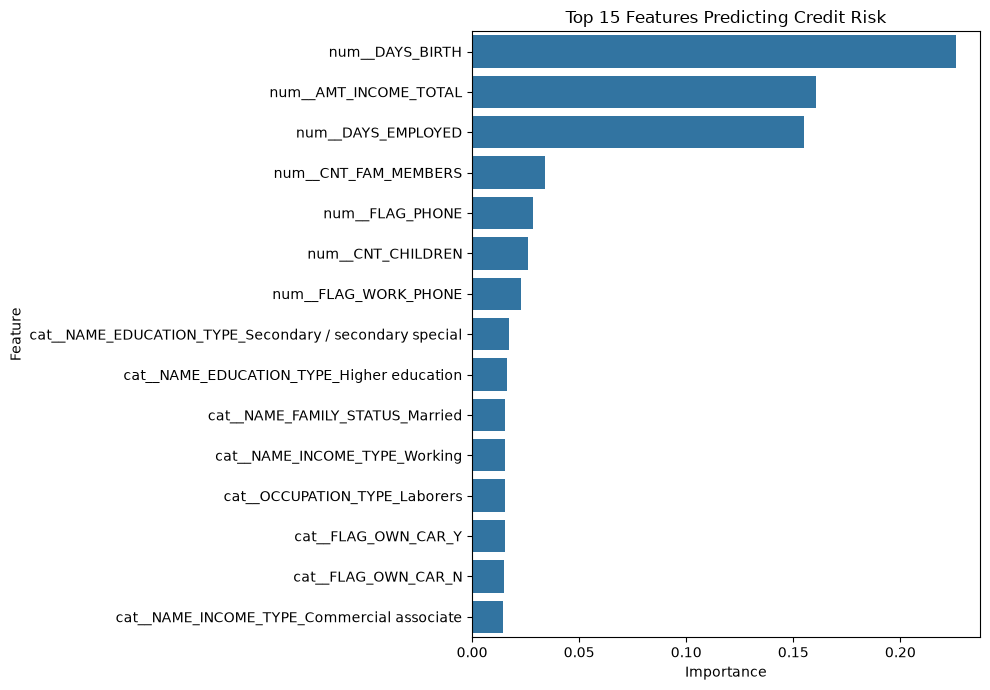

In [6]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Separate features and target
X = df.drop(columns=["credit_risk"])
y = df["credit_risk"]

# Identify column types
num_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Numerical preprocessing
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Fit model for exploratory feature importance
rf_pipeline.fit(X, y)

# Extract feature importance
feature_names = (
    rf_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = (
    rf_pipeline.named_steps["model"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

# Visualize top features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Predicting Credit Risk")
plt.tight_layout()
plt.show()
